# 05 — CAMeLBERT gelé et tête de classification

Nous comparons ici une **représentation préentraînée** aux références TF-IDF et BiGRU. Un encodeur transforme chaque texte en nombres ; la tête apprend à choisir le sentiment ou la variété. **Les 108 490 752 paramètres du backbone restent gelés.** Ce notebook ne réalise pas encore le fine-tuning complet ni LoRA.

Contributions partielles à **L05, L07 et L12**. Protocole : `docs/44_protocole_encodeur_gele.md`. Train/validation v2 ; aucun test officiel dans les métriques.

## Avant de lancer

Ouvrir depuis le dépôt avec le noyau **TuniScope (notebooks)**. Les scripts et les sources autorisées sont nécessaires. L'environnement séparé se prépare une fois avec `sh scripts/encoder_uv.sh sync --locked`. Le téléchargement explicite des poids déjà épinglés se fait une fois avec `sh scripts/project_uv.sh run --locked python scripts/fetch_camelbert_encoder.py --download`. Le notebook fonctionne ensuite hors ligne et ne télécharge rien implicitement.

**FULL par défaut** : contrôle de 100 exemples, puis tout le train et toute la validation, trois graines par tâche. `smoke` s'arrête au petit essai ; `replay` vérifie un run FULL existant sans entraîner ; `off` ne charge rien. Kaggle/CUDA reste à tester réellement ; les corpus y sont déposés manuellement dans un espace privé avec adaptation des chemins.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'scripts/encoder_uv.sh').is_file()), None)
if ROOT is None:
    raise RuntimeError('Ouvrir le notebook depuis le dépôt ou son dossier notebooks/.')
sys.path.insert(0, str(ROOT / 'scripts'))
from frozen_encoder_notebook_support import notebook_run, figure_paths

TRAINING_MODE = os.environ.get('TUNISCOPE_FROZEN_MODE', 'full')
REPLAY_RUN = os.environ.get('TUNISCOPE_FROZEN_RUN',
    'outputs/frozen_encoder/2026-11-04_camelbert_frozen_mps_full')
if TRAINING_MODE not in {'full', 'smoke', 'replay', 'off'}:
    raise ValueError('Choisir full, smoke, replay ou off.')
print('Mode effectif :', TRAINING_MODE.upper())


Mode effectif : FULL


## 1. Encodage fixe, puis apprentissage

1. Le tokenizer WordPiece préentraîné découpe le texte (128 sous-mots au maximum, CLS/SEP compris).
2. BERT calcule un vecteur de 768 nombres par token. Il reste en mode évaluation, sans gradient ni dropout.
3. La moyenne masquée ignore le padding et inclut CLS/SEP. Un vecteur par texte est conservé dans le dossier privé du run.
4. Une couche linéaire 768→2 ou 768→3 apprend uniquement sur le train. Les vecteurs sont réutilisés pour les trois graines : nous ne relançons pas BERT à chaque époque.
5. Nous retenons l'époque de meilleur macro-F1 sur la validation, avec arrêt anticipé. Les trois graines sont toutes rapportées.

Les logs affichent d'abord « Encodage », puis les époques de la **tête**. Nous vérifions l'empreinte du backbone avant/après pour confirmer qu'il n'a pas appris.


In [2]:
run_directory = None
run_result = None
if TRAINING_MODE != 'off':
    run_directory, run_result = notebook_run(TRAINING_MODE, REPLAY_RUN)
    print('\nDossier du run :', run_directory)
else:
    print('Mode OFF : aucun chargement et aucun entraînement.')


Chargement local CAMeLBERT sur mps — aucun téléchargement implicite.
TSAC train : 100 textes
  Encodage 16/100 textes
  Encodage 100/100 textes
TSAC validation : 100 textes
  Encodage 16/100 textes
  Encodage 100/100 textes
  Graine 42 époque 01 | perte train 0.6985 | perte val 0.6904 | macro-F1 0.503748
  Graine 42 époque 02 | perte train 0.6612 | perte val 0.6784 | macro-F1 0.548440
MADAR train : 100 textes
  Encodage 16/100 textes
  Encodage 100/100 textes
MADAR validation : 100 textes
  Encodage 16/100 textes
  Encodage 100/100 textes
  Graine 42 époque 01 | perte train 1.0589 | perte val 0.9721 | macro-F1 0.291478
  Graine 42 époque 02 | perte train 0.9505 | perte val 0.9117 | macro-F1 0.239909
CAMeLBERT gelé — SMOKE — encodeur mps, tête CPU
Train/validation v2 ; test officiel non évalué.
Backbone : 108,490,752 paramètres, 0 entraînable.
Corpus    Graine   Accuracy   Macro-F1   Époque retenue
TSAC      42       0.560000   0.548440   2
MADAR     42       0.510000   0.291478   1
TSA

## 2. Lire les résultats

Accuracy = proportion de labels corrects. Macro-F1 = moyenne des F1 de chaque classe, notre métrique principale pour ne pas masquer une classe moins fréquente. L'écart-type mesure la variation entre graines. Un score SMOKE ne se compare pas aux scores FULL.

La vérification recharge toutes les têtes, recalcule leurs prédictions sur toute la validation et réencode dix textes par tâche avec BERT pour contrôler les vecteurs. Les modèles ne sont pas automatiquement déployés dans l'application.


In [3]:
if run_result is not None:
    print('Corpus   Graine  Accuracy   Macro-F1   Époque  Paramètres appris')
    for result in run_result['results']:
        print(f"{result['corpus'].upper():<9}{result['seed']:<8}"
              f"{result['metrics']['accuracy']:<11.6f}{result['metrics']['macro_f1']:<11.6f}"
              f"{result['best_epoch']:<8}{result['trainable_parameters']}")
    for corpus, item in run_result['aggregates'].items():
        spread = item['sample_std_macro_f1']
        suffix = f" ± {spread:.6f}" if spread is not None else ' (une graine, essai seulement)'
        print(f"{corpus.upper()} macro-F1 : {item['mean_macro_f1']:.6f}{suffix}")
    print('Matériel encodeur :', run_result['device'], '| tête : CPU')
    print('Encodeur inchangé :', run_result['encoder_unchanged'])
    print('Test officiel utilisé :', run_result['test_loaded'])
    print(f"Durée du run : {run_result['total_seconds']:.1f} s")


Corpus   Graine  Accuracy   Macro-F1   Époque  Paramètres appris
TSAC     13      0.841601   0.841001   16      1538
TSAC     42      0.848365   0.847584   25      1538
TSAC     2026    0.846110   0.845241   23      1538
MADAR    13      0.923750   0.919112   3       2307
MADAR    42      0.925000   0.920714   7       2307
MADAR    2026    0.930000   0.925954   14      2307
TSAC macro-F1 : 0.844608 ± 0.003337
MADAR macro-F1 : 0.921926 ± 0.003579
Matériel encodeur : mps | tête : CPU
Encodeur inchangé : True
Test officiel utilisé : False
Durée du run : 85.5 s


## 3. Courbes et matrices de confusion

Pour chaque tâche et graine : les pertes montrent l'apprentissage de la tête ; le macro-F1 montre son résultat de validation ; la matrice compte les labels réels (lignes) et prédits (colonnes). La ligne verticale indique l'époque retenue.

Les PNG sont générés depuis **ce même run**, enregistrés dans son sous-dossier `figures/`, puis affichés. Aucun nouvel entraînement n'est nécessaire pour les exporter. Une empreinte relie chaque figure au fichier de résultats.


Verified full: 6 heads replayed, metrics recalculated; ten-row reencoding/task: False
Figures enregistrées : /Users/elghoth/Desktop/NLP Project/outputs/frozen_encoder/notebooks/b52a2cd979f64a409ec95be132239553_full/figures
Images enregistrées dans : /Users/elghoth/Desktop/NLP Project/outputs/frozen_encoder/notebooks/b52a2cd979f64a409ec95be132239553_full/figures


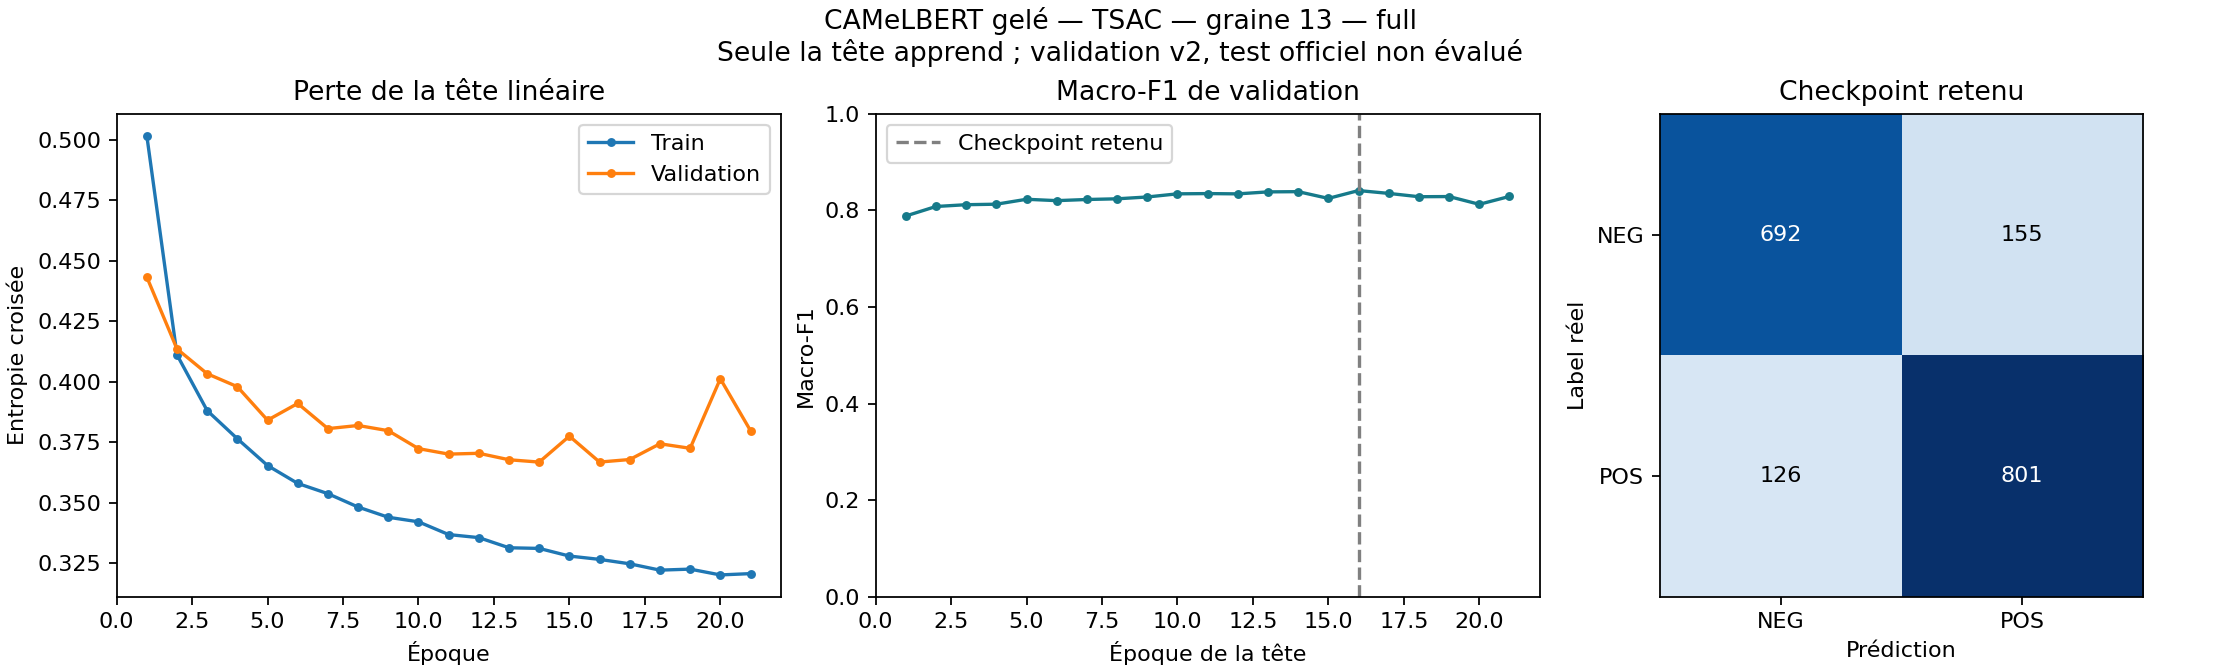

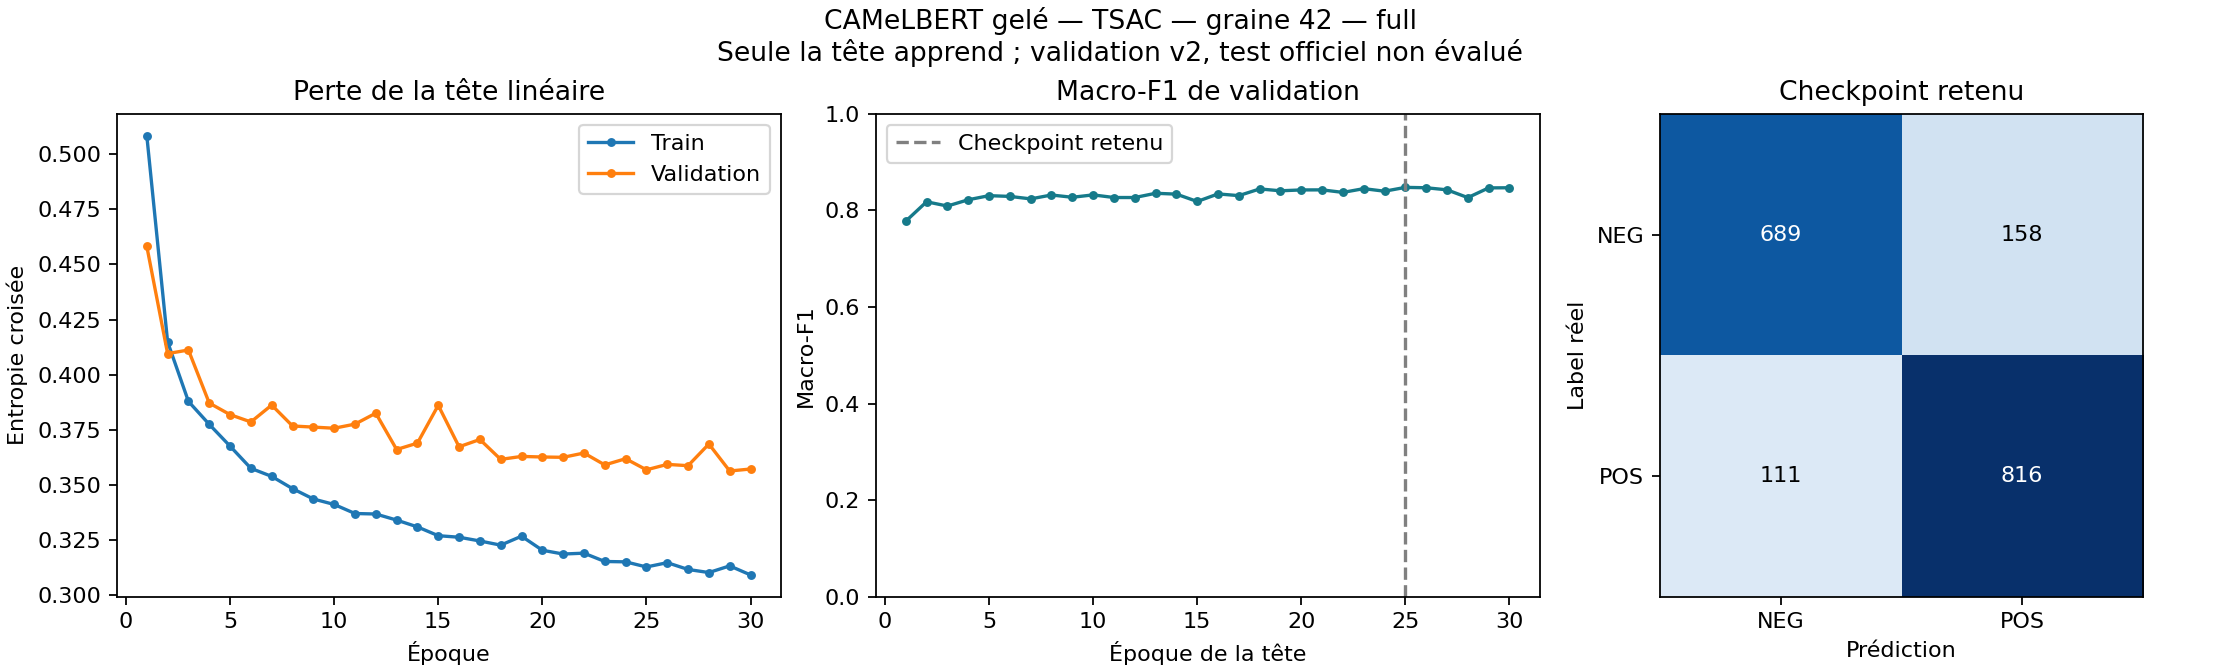

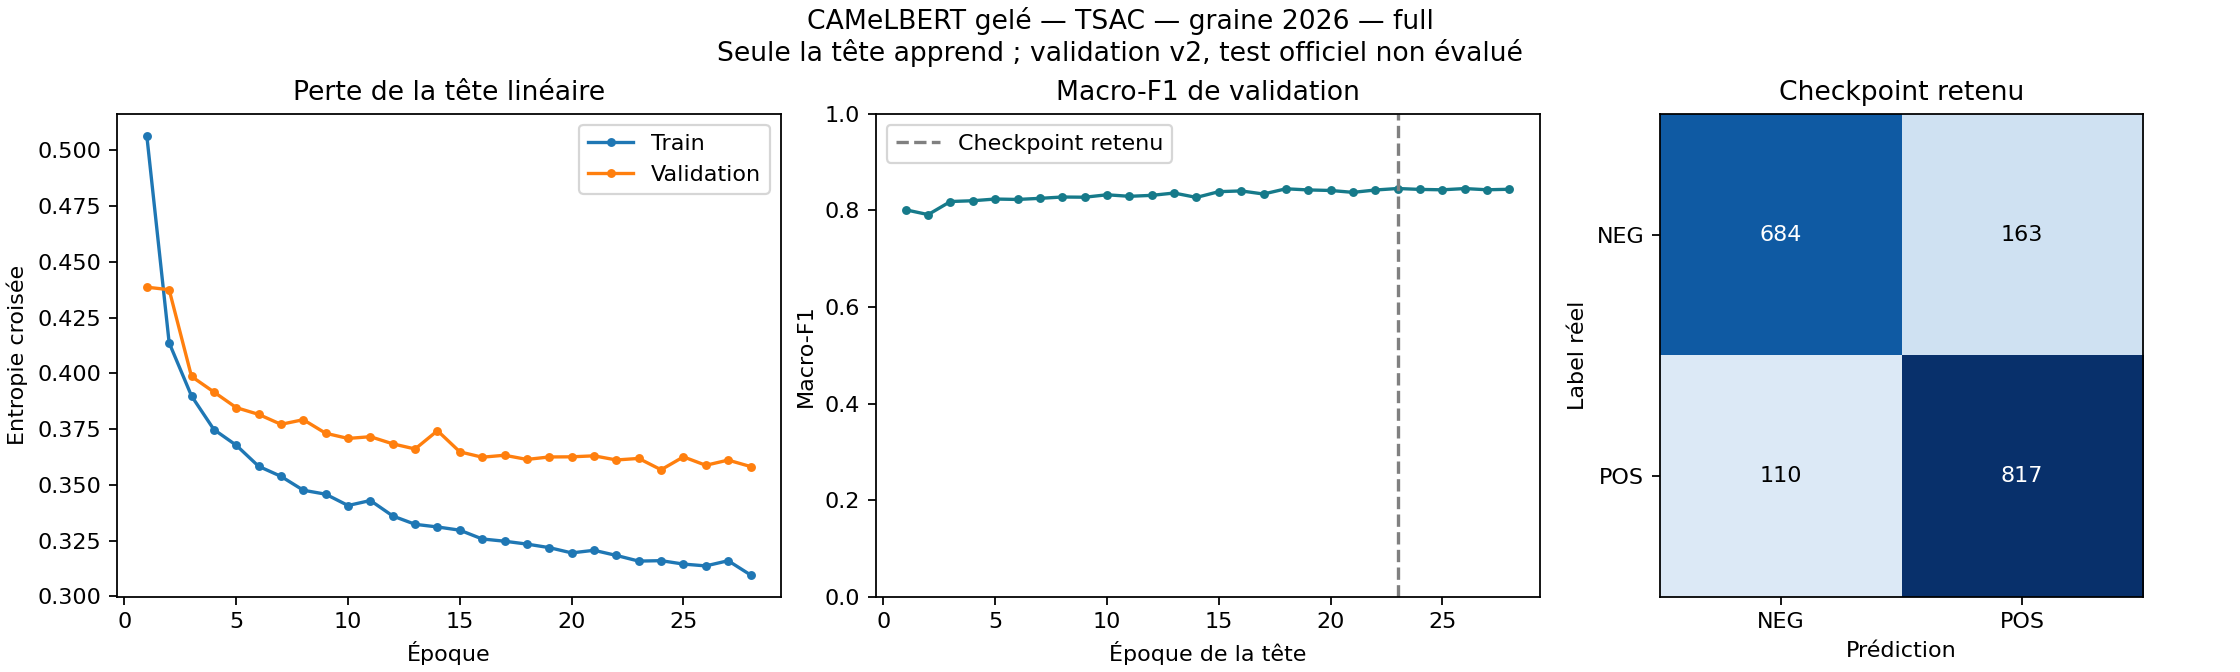

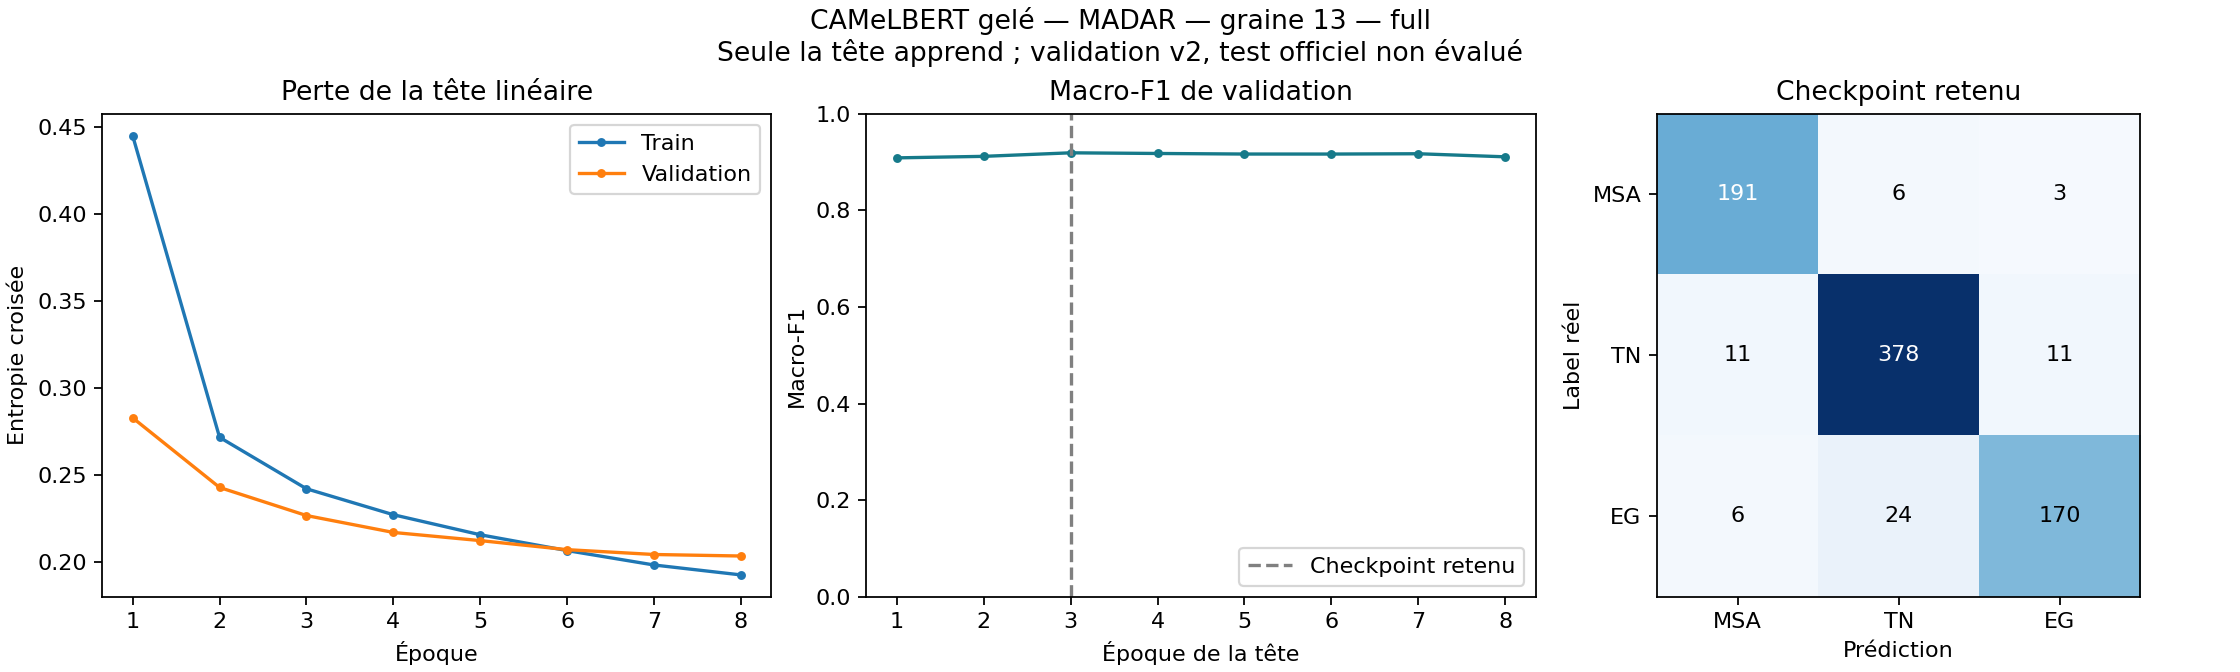

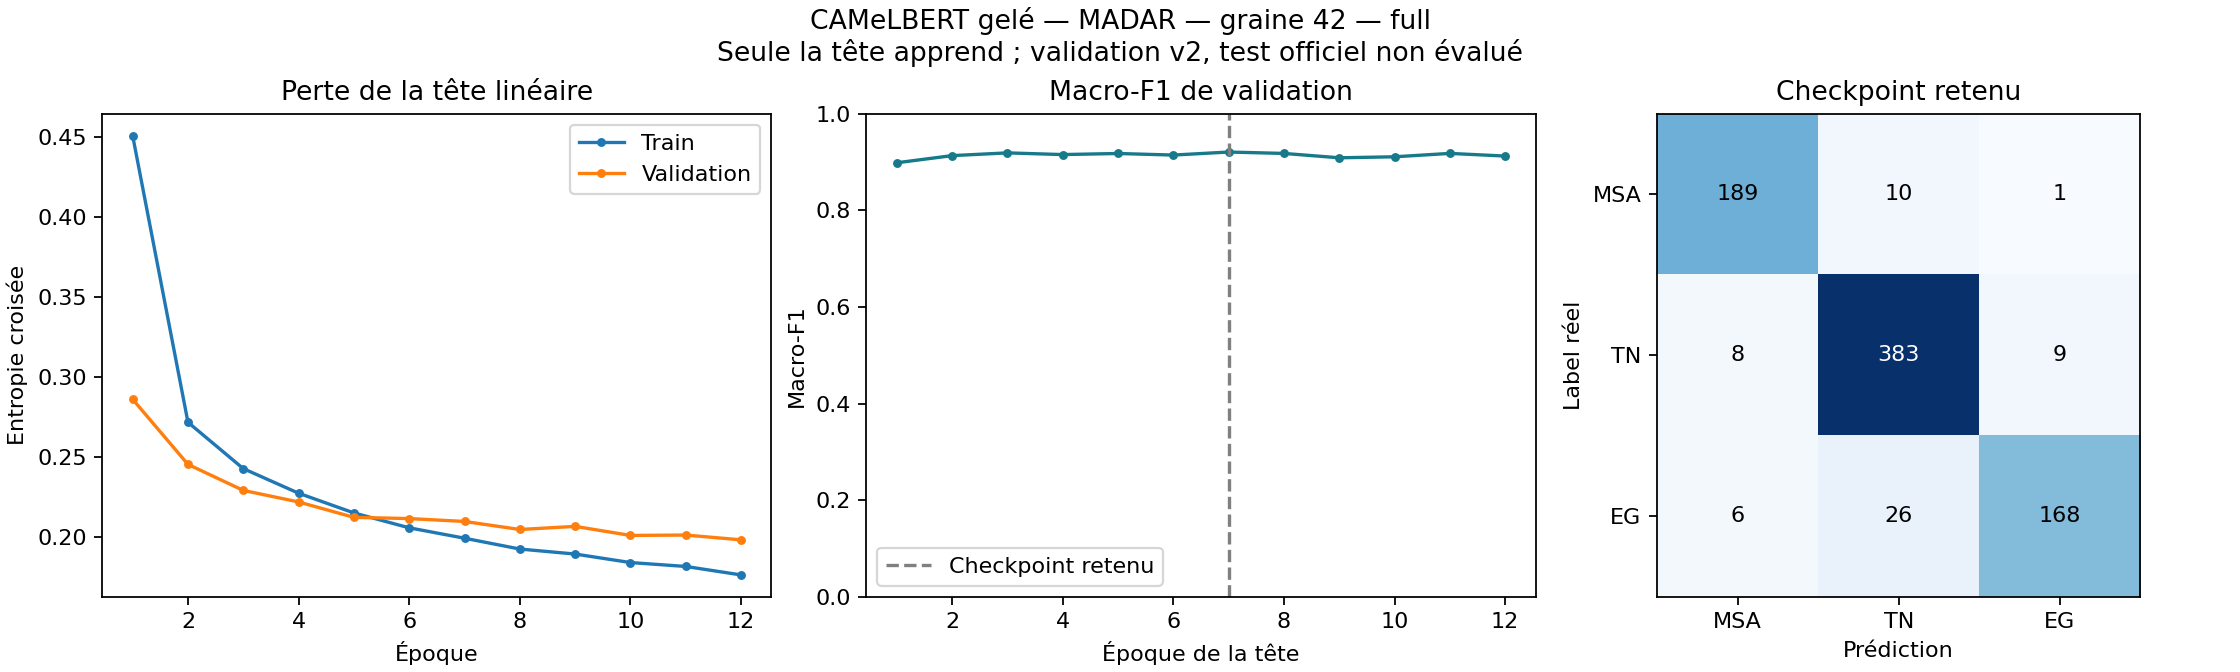

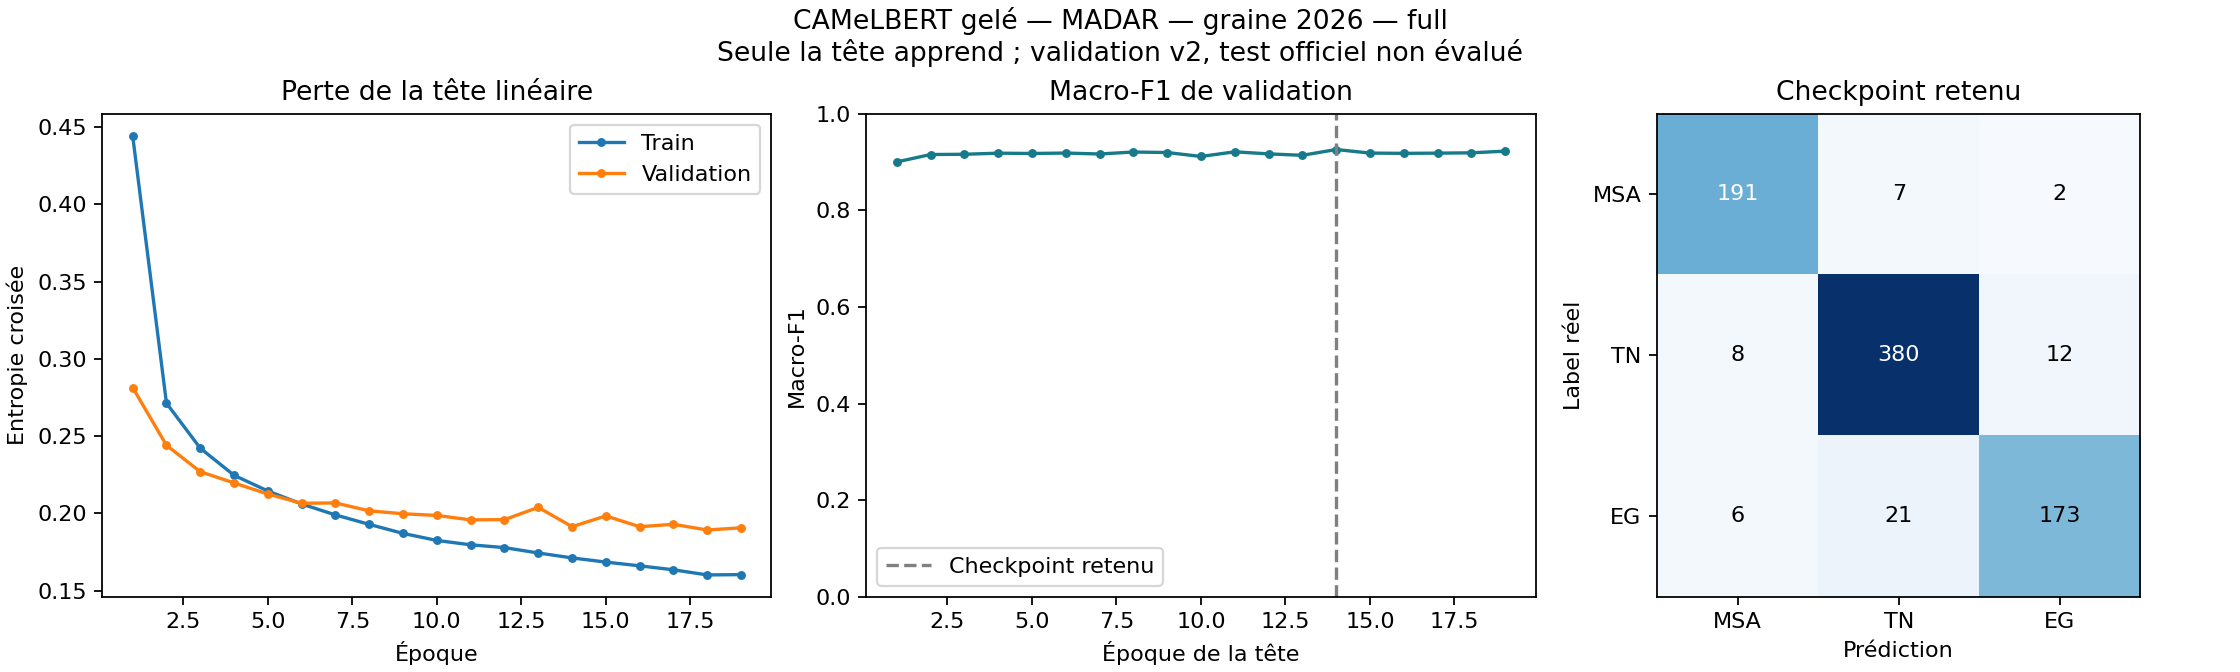

In [4]:
if run_directory is not None:
    from IPython.display import display, Image
    images = figure_paths(run_directory)
    print('Images enregistrées dans :', run_directory / 'figures')
    for path in images:
        display(Image(filename=str(path)))


## Ce que cette étape permet de conclure

Nous mesurons l'utilité des représentations préentraînées sans adaptation du backbone. Cela ne prédit pas automatiquement le résultat du futur fine-tuning. Une comparaison contrôlée gelé/adapté devra maintenir le pooling et la tête constants, ou signaler les différences de méthode.

L05 reste partiel : le fine-tuning complet, l'inférence dédiée, les essais CUDA et les preuves finales restent à produire. Le test officiel sera évalué seulement après verrouillage du protocole final.
